# 02 · Preparação dos Dados
Fase 3 do CRISP-DM: limpar os tipos, criar variáveis e montar o **perfil de cada jogador** (uma linha por pessoa).

> **Dados:** enquanto a turma não joga, os notebooks usam `data/processed/capturas_demo.csv` (fictício, gerado por `python -m src.exemplo`). Para usar os dados reais, baixe o CSV na página **Avaliação** do app e salve como `data/processed/avaliacao_juizes.csv`: os notebooks passam a ler esse arquivo sozinhos. As conclusões abaixo só valem de verdade com os dados reais.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.temas import POR_ID, TEMAS

sns.set_theme(style="whitegrid")
# Dados reais (CSV baixado da página Avaliação) quando existirem; senão, os fictícios de src/exemplo.py
REAL = RAIZ / "data" / "processed" / "avaliacao_juizes.csv"
DEMO = RAIZ / "data" / "processed" / "capturas_demo.csv"
ARQUIVO = REAL if REAL.exists() else DEMO
df = pd.read_csv(ARQUIVO, parse_dates=["criado_em"])
NOME_TEMA = {t.id: t.nome for t in TEMAS} | {"nenhum": "nenhum"}
print("Arquivo:", ARQUIVO.name, "| DADOS FICTÍCIOS" if ARQUIVO == DEMO else "| dados reais")
print(df.shape)
from src.clustering import matriz_perfis
from src.jogo import eh_generico, normalizar, normalizar_juiz

Arquivo: capturas_demo.csv | DADOS FICTÍCIOS
(198, 29)


## 1. Limpeza
O CSV traz `True`/`False` como texto quando há nulos na coluna. Padronizamos os booleanos, o tema *nenhum* e as probabilidades do CLIP (0 a 1).

In [2]:
def booleano(s):
    return s.map(lambda v: v if isinstance(v, bool) else str(v).strip().lower() in {"true", "1", "sim"} if pd.notna(v) else pd.NA).astype("boolean")

limpo = df.copy()
for col in ("foto_real", "clip_foto_real", "aceita", "do_dia"):
    limpo[col] = booleano(limpo[col])
limpo["tema"] = limpo["tema"].fillna("nenhum")
limpo["clip_tema"] = limpo["clip_tema"].fillna("nenhum")
for col in ("clip_prob_tema", "clip_prob_tela", "confianca"):
    assert limpo[col].dropna().between(0, 1).all(), col
assert limpo["tema"].isin(list(NOME_TEMA)).all()
limpo.dtypes

usuario                      str
criado_em         datetime64[us]
cidade                       str
tema                         str
achado                       str
confianca                float64
foto_real                boolean
juiz                         str
clip_tema                    str
clip_foto_real           boolean
clip_prob_tema           float64
clip_prob_tela           float64
clip_rank_tema           float64
contestada                   str
mirante                   object
tipo_lugar                   str
clima                        str
km_anterior              float64
min_anterior             float64
aceita                   boolean
motivo                       str
do_dia                   boolean
base                       int64
novidade                   int64
raridade                   int64
extra                      int64
lupa                       int64
meta                       int64
pontos                     int64
dtype: object

## 2. Variáveis derivadas
- `hora`, `dia_semana`, `data`: quando a foto foi tirada;
- `especifico`: o achado diz o modelo, a espécie ou a raça (não só "carro" ou "pássaro");
- `concorda`: o CLIP escolheu o mesmo tema do juiz principal;
- `recusa`: o motivo resumido (sem o detalhe entre parênteses).

In [3]:
limpo["hora"] = limpo["criado_em"].dt.hour
limpo["dia_semana"] = limpo["criado_em"].dt.day_of_week
limpo["data"] = limpo["criado_em"].dt.date
limpo["especifico"] = [t != "nenhum" and bool(a) and not eh_generico(t, normalizar(a))
                        for t, a in zip(limpo["tema"], limpo["achado"].fillna(""))]
limpo["concorda"] = (limpo["juiz"].map(normalizar_juiz) == "ia+clip") & (limpo["tema"] == limpo["clip_tema"])
limpo["recusa"] = limpo["motivo"].str.replace(r" \(.*\)$", "", regex=True)
limpo[["tema", "achado", "especifico", "concorda", "recusa"]].head(10)

,tema,achado,especifico,concorda,recusa
0,passaros,sabiá-laranjeira,True,True,NaN
1,plantas,espada-de-são-jorge,True,True,NaN
2,passaros,gavião-carijó,True,True,NaN
3,passaros,gavião-carijó,True,True,você já achou isso hoje
4,plantas,bromélia,True,True,NaN
5,passaros,pombo,True,True,NaN
6,passaros,garça-branca,True,False,os juízes discordaram do tema
7,passaros,sabiá-laranjeira,True,True,NaN
8,plantas,costela-de-adão,True,True,NaN
9,plantas,espada-de-são-jorge,True,False,NaN


## 3. Perfil de cada jogador
Cada pessoa vira um vetor com a **proporção** das suas fotos aceitas em cada tema (cada linha soma 1). Proporção, e não contagem, para quem joga muito não dominar o agrupamento. Pessoas com menos de 5 fotos aceitas ficam de fora (perfil pouco confiável). É o mesmo vetor que o app usa no estilo de jogador (`src/jogo.estilo_jogador`).

In [4]:
IDS = [t.id for t in TEMAS]
perfis = matriz_perfis(limpo[limpo["aceita"]], minimo=5, coluna="tema", valores=IDS)
assert (perfis.sum(axis=1).round(6) == 1).all()
print(len(perfis), "jogadores")
perfis.rename(columns=NOME_TEMA).round(2)

9 jogadores


tema,Carros,Plantas e flores,Pássaros,Cachorros e gatos,Peças e periféricos de computador
u01,0.00,0.63,0.37,0.00,0.00
u02,0.00,0.20,0.00,0.80,0.00
u03,0.27,0.00,0.00,0.00,0.73
u04,0.74,0.00,0.00,0.00,0.26
u05,0.00,0.50,0.50,0.00,0.00
u06,0.00,0.27,0.00,0.73,0.00
u07,0.67,0.00,0.00,0.00,0.33
u08,0.82,0.00,0.00,0.00,0.18
u09,0.35,0.00,0.00,0.00,0.65


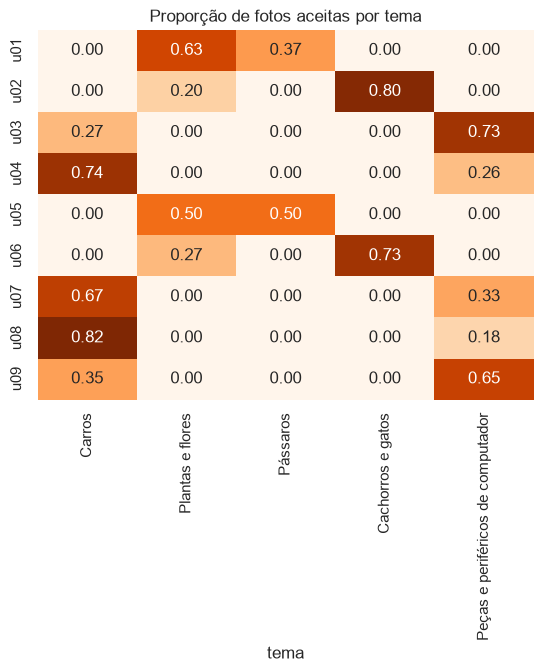

In [5]:
sns.heatmap(perfis.rename(columns=NOME_TEMA), annot=True, fmt=".2f", cmap="Oranges", cbar=False)
plt.title("Proporção de fotos aceitas por tema");

## 4. Salvar
O notebook 03 lê estes dois arquivos.

In [6]:
SAIDA = RAIZ / "data" / "processed"
limpo.to_csv(SAIDA / "capturas_limpas.csv", index=False)
perfis.to_csv(SAIDA / "perfis_jogadores.csv", index_label="usuario")
print("ok:", len(limpo), "capturas e", len(perfis), "perfis")

ok: 198 capturas e 9 perfis
